In [2]:
print("News Category Classification Project")
print("Environment is working!")

News Category Classification Project
Environment is working!


In [3]:
import zipfile
import json
import os

zip_path = "../data/raw/News_Category_Dataset_v3.json.zip"
extract_path = "../data/raw"

# Extract the dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# Find the extracted JSON file
json_path = "../data/raw/News_Category_Dataset_v3.json"

# Load the dataset
with open(json_path, "r", encoding="utf-8") as file:
    data = [json.loads(line) for line in file]

print("Dataset loaded successfully!")
print("Number of articles:", len(data))

Dataset extracted successfully!
Dataset loaded successfully!
Number of articles: 209527


In [4]:
# Inspect the first article
print("First article:")
print(data[0])

First article:
{'link': 'https://www.huffpost.com/entry/covid-boosters-uptake-us_n_632d719ee4b087fae6feaac9', 'headline': 'Over 4 Million Americans Roll Up Sleeves For Omicron-Targeted COVID Boosters', 'category': 'U.S. NEWS', 'short_description': 'Health experts said it is too early to predict whether demand would match up with the 171 million doses of the new boosters the U.S. ordered for the fall.', 'authors': 'Carla K. Johnson, AP', 'date': '2022-09-23'}


In [5]:
# Check the dataset structure
print("Number of articles:", len(data))
print("Columns:", data[0].keys())

Number of articles: 209527
Columns: dict_keys(['link', 'headline', 'category', 'short_description', 'authors', 'date'])


In [6]:
# Show the different news categories
categories = sorted(set(article["category"] for article in data))

print("Number of categories:", len(categories))
print("\nCategories:")
for category in categories:
    print(category)

Number of categories: 42

Categories:
ARTS
ARTS & CULTURE
BLACK VOICES
BUSINESS
COLLEGE
COMEDY
CRIME
CULTURE & ARTS
DIVORCE
EDUCATION
ENTERTAINMENT
ENVIRONMENT
FIFTY
FOOD & DRINK
GOOD NEWS
GREEN
HEALTHY LIVING
HOME & LIVING
IMPACT
LATINO VOICES
MEDIA
MONEY
PARENTING
PARENTS
POLITICS
QUEER VOICES
RELIGION
SCIENCE
SPORTS
STYLE
STYLE & BEAUTY
TASTE
TECH
THE WORLDPOST
TRAVEL
U.S. NEWS
WEDDINGS
WEIRD NEWS
WELLNESS
WOMEN
WORLD NEWS
WORLDPOST


In [7]:
import re

def clean_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Combine headline and short description
texts = []

for article in data:
    headline = article.get("headline", "")
    description = article.get("short_description", "")

    combined_text = headline + " " + description
    texts.append(clean_text(combined_text))


print("Text preprocessing completed!")
print("Number of processed texts:", len(texts))

Text preprocessing completed!
Number of processed texts: 209527


In [8]:
print("Original headline:")
print(data[0]["headline"])

print("\nCleaned text:")
print(texts[0])

Original headline:
Over 4 Million Americans Roll Up Sleeves For Omicron-Targeted COVID Boosters

Cleaned text:
over million americans roll up sleeves for omicron targeted covid boosters health experts said it is too early to predict whether demand would match up with the million doses of the new boosters the u s ordered for the fall


In [9]:
labels = [article["category"] for article in data]

print("Labels created successfully!")
print("Number of labels:", len(labels))
print("First 10 labels:", labels[:10])

Labels created successfully!
Number of labels: 209527
First 10 labels: ['U.S. NEWS', 'U.S. NEWS', 'COMEDY', 'PARENTING', 'U.S. NEWS', 'U.S. NEWS', 'U.S. NEWS', 'WORLD NEWS', 'CULTURE & ARTS', 'WORLD NEWS']


In [10]:
import sys

print(sys.executable)
print(sys.version)

C:\Users\Vanitha Vani\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [12]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "scikit-learn"
])

print("scikit-learn installation completed!")

scikit-learn installation completed!


In [13]:
import sklearn

print("scikit-learn is working!")
print("Version:", sklearn.__version__)

scikit-learn is working!
Version: 1.9.0


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Train/test split completed!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Train/test split completed!
Training samples: 167621
Testing samples: 41906


In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

# Learn vocabulary from training data and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF vectorization completed!")
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

TF-IDF vectorization completed!
Training TF-IDF shape: (167621, 50000)
Testing TF-IDF shape: (41906, 50000)


In [16]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_tfidf, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [17]:
from sklearn.svm import LinearSVC

# Create Linear SVM model
svm_model = LinearSVC(
    random_state=42
)

# Train the model
svm_model.fit(X_train_tfidf, y_train)

print("Linear SVM training completed!")

Linear SVM training completed!


In [18]:
from sklearn.naive_bayes import MultinomialNB

# Create Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes training completed!")

Naive Bayes training completed!


In [19]:
# Generate predictions for each model

y_pred_logistic = logistic_model.predict(X_test_tfidf)
y_pred_nb = nb_model.predict(X_test_tfidf)
y_pred_svm = svm_model.predict(X_test_tfidf)

print("Predictions generated successfully!")

Predictions generated successfully!


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate metrics
results = []

models_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Naive Bayes": y_pred_nb,
    "Linear SVM": y_pred_svm
}

for model_name, predictions in models_predictions.items():
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average="weighted", zero_division=0)
    recall = recall_score(y_test, predictions, average="weighted", zero_division=0)
    f1 = f1_score(y_test, predictions, average="weighted", zero_division=0)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

print("Model evaluation completed!")

for result in results:
    print("\n", result["Model"])
    print("Accuracy :", round(result["Accuracy"], 4))
    print("Precision:", round(result["Precision"], 4))
    print("Recall   :", round(result["Recall"], 4))
    print("F1-Score :", round(result["F1-Score"], 4))

Model evaluation completed!

 Logistic Regression
Accuracy : 0.6029
Precision: 0.6005
Recall   : 0.6029
F1-Score : 0.5729

 Naive Bayes
Accuracy : 0.4587
Precision: 0.5823
Recall   : 0.4587
F1-Score : 0.3656

 Linear SVM
Accuracy : 0.6048
Precision: 0.5874
Recall   : 0.6048
F1-Score : 0.5897


In [21]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# Get all category names
classes = sorted(set(y_test))

# Convert true labels to binary format
y_test_binary = label_binarize(y_test, classes=classes)

print("Number of classes:", len(classes))
print("ROC-AUC preparation completed!")

Number of classes: 42
ROC-AUC preparation completed!


In [22]:
# Get decision/probability scores

logistic_scores = logistic_model.predict_proba(X_test_tfidf)
nb_scores = nb_model.predict_proba(X_test_tfidf)
svm_scores = svm_model.decision_function(X_test_tfidf)

# Calculate multiclass ROC-AUC
logistic_auc = roc_auc_score(
    y_test_binary,
    logistic_scores,
    multi_class="ovr",
    average="weighted"
)

nb_auc = roc_auc_score(
    y_test_binary,
    nb_scores,
    multi_class="ovr",
    average="weighted"
)

svm_auc = roc_auc_score(
    y_test_binary,
    svm_scores,
    multi_class="ovr",
    average="weighted"
)

print("ROC-AUC results:")
print("Logistic Regression:", round(logistic_auc, 4))
print("Naive Bayes:", round(nb_auc, 4))
print("Linear SVM:", round(svm_auc, 4))

ROC-AUC results:
Logistic Regression: 0.9571
Naive Bayes: 0.929
Linear SVM: 0.9407


In [25]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "pandas"
])

print("Pandas installation completed!")

Pandas installation completed!


In [26]:
import pandas as pd

print("Pandas is working!")
print("Version:", pd.__version__)

Pandas is working!
Version: 3.0.5


In [48]:
results_df = pd.DataFrame(results)

print("Results table recreated successfully!")
results_df

Results table recreated successfully!


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.602945,0.600484,0.602945,0.572937
1,Naive Bayes,0.458669,0.582339,0.458669,0.365576
2,Linear SVM,0.604806,0.587443,0.604806,0.589741


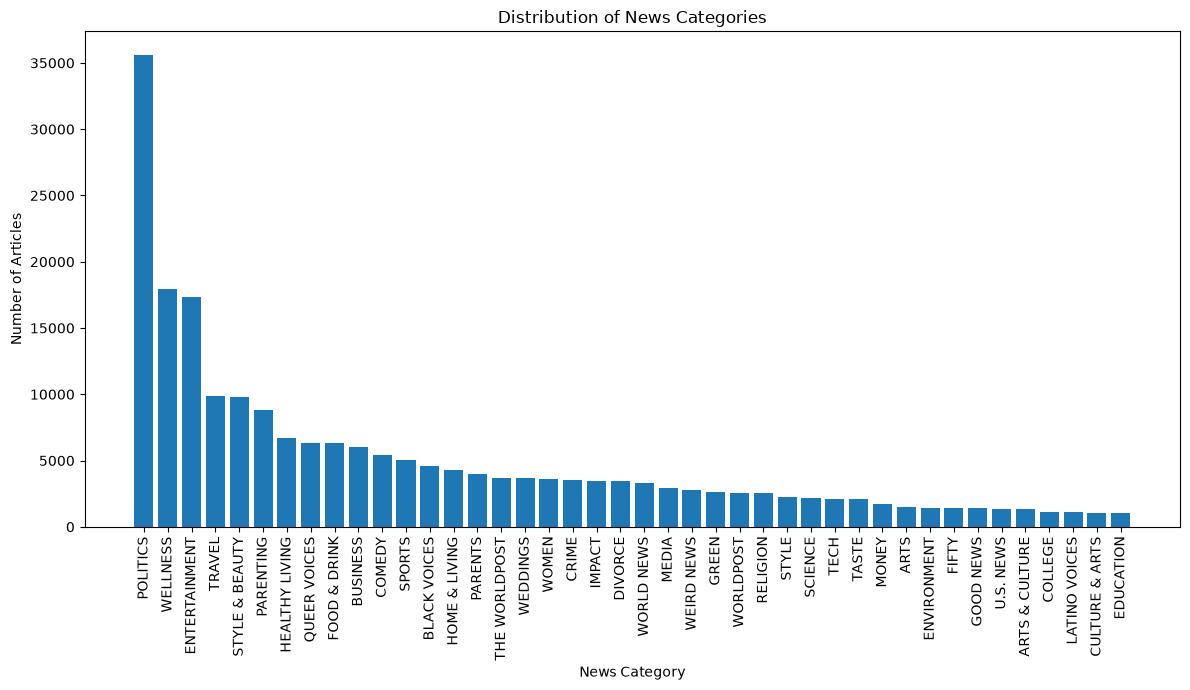

Fig. 1 saved successfully!
../reports/category_distribution.png


In [43]:
import matplotlib.pyplot as plt
from collections import Counter

# Count articles in each category
category_counts = Counter(labels)

# Sort categories by number of articles
categories_sorted = sorted(category_counts, key=category_counts.get, reverse=True)
counts_sorted = [category_counts[c] for c in categories_sorted]

plt.figure(figsize=(12, 7))

plt.bar(categories_sorted, counts_sorted)

plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.title("Distribution of News Categories")

plt.xticks(rotation=90)
plt.tight_layout()

# Save the figure
plt.savefig("../reports/category_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

print("Fig. 1 saved successfully!")
print("../reports/category_distribution.png")

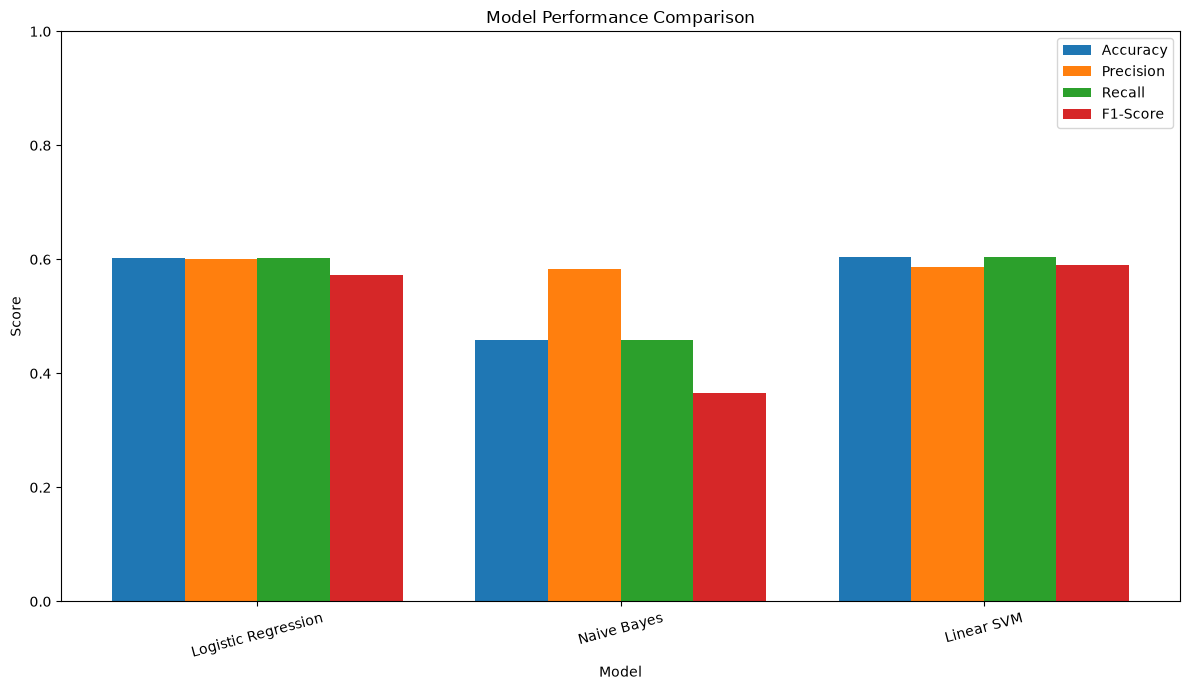

Fig. 2 saved successfully!
../reports/model_performance.png


In [44]:
import matplotlib.pyplot as plt

# Prepare model performance data
models = results_df["Model"]

accuracy = results_df["Accuracy"]
precision = results_df["Precision"]
recall = results_df["Recall"]
f1 = results_df["F1-Score"]

x = range(len(models))
width = 0.2

plt.figure(figsize=(12, 7))

plt.bar([i - 1.5 * width for i in x], accuracy, width, label="Accuracy")
plt.bar([i - 0.5 * width for i in x], precision, width, label="Precision")
plt.bar([i + 0.5 * width for i in x], recall, width, label="Recall")
plt.bar([i + 1.5 * width for i in x], f1, width, label="F1-Score")

plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Model Performance Comparison")

plt.xticks(list(x), models, rotation=15)
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()

# Save the figure
plt.savefig("../reports/model_performance.png", dpi=300, bbox_inches="tight")

plt.show()

print("Fig. 2 saved successfully!")
print("../reports/model_performance.png")

Best model: Linear SVM


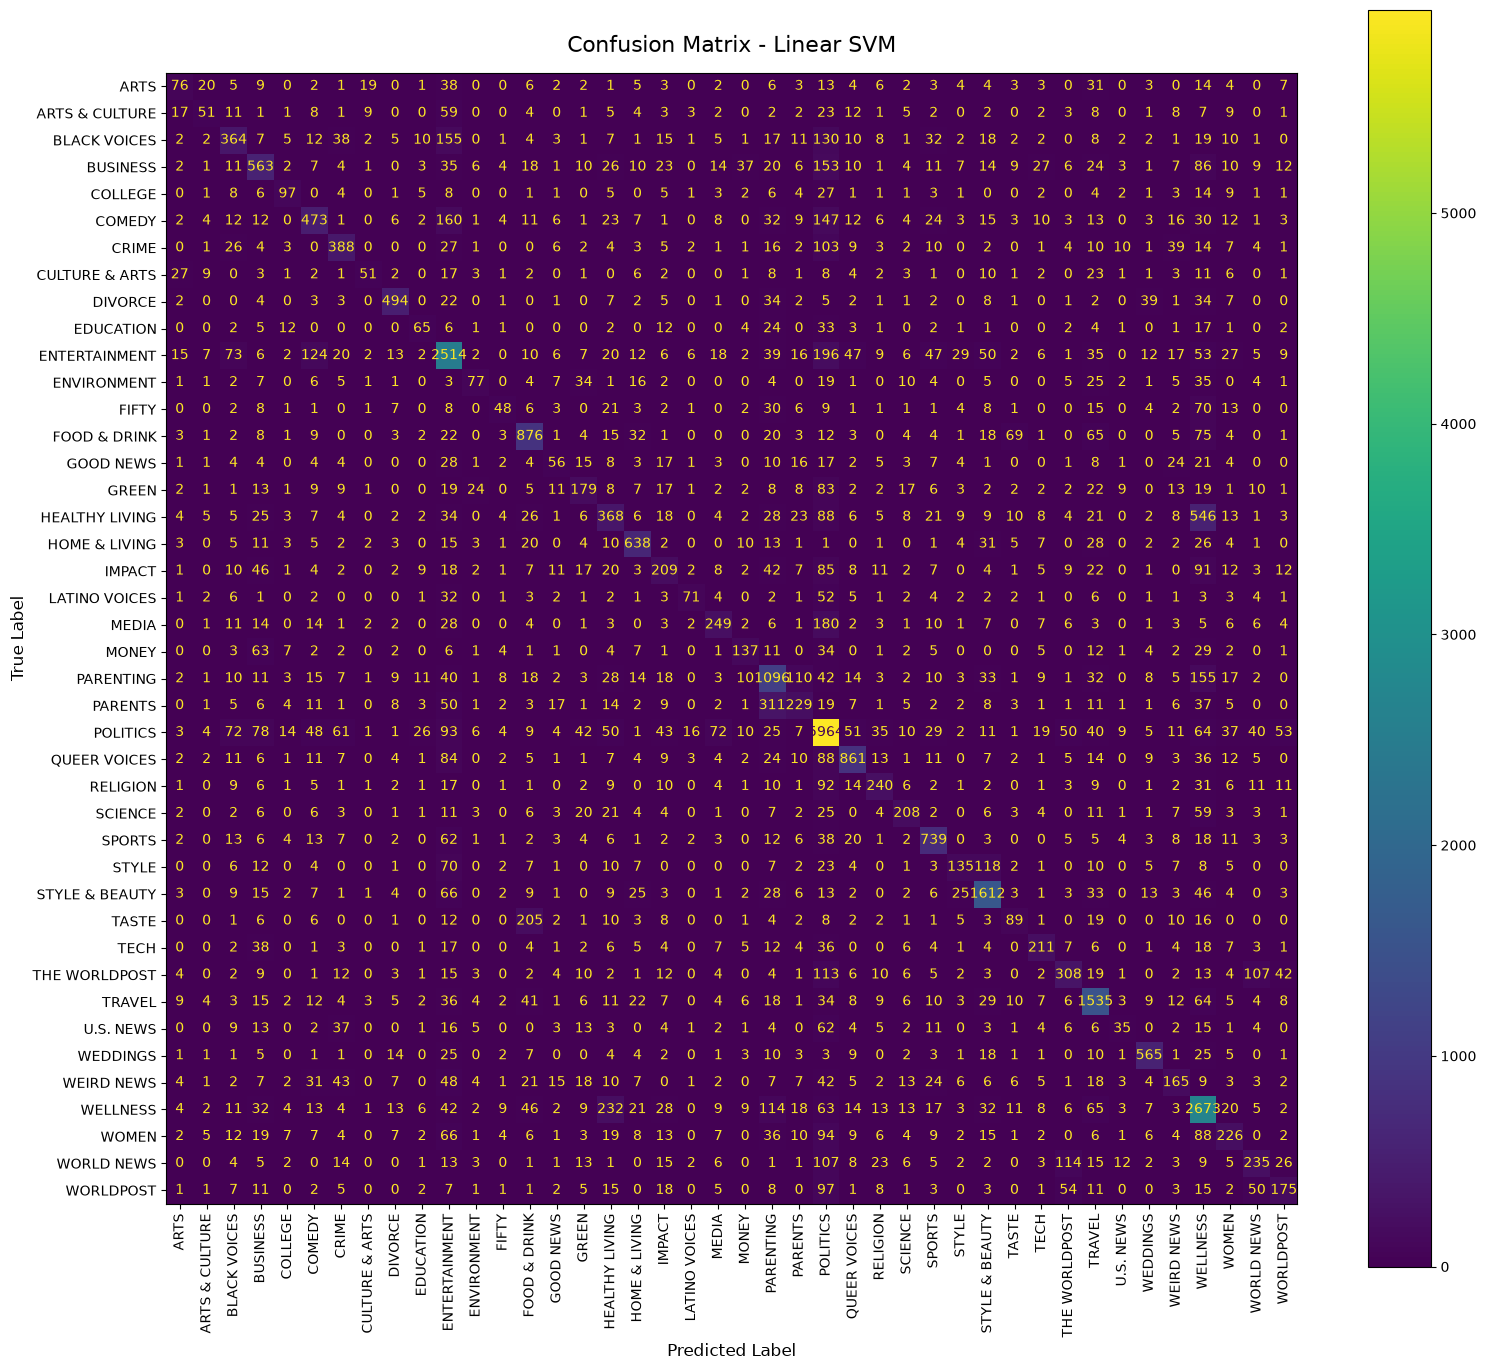

Fig. 3 saved successfully!
Best model: Linear SVM


In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Select the best model based on F1-Score
best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

print("Best model:", best_model_name)

# Select predictions
if best_model_name == "Logistic Regression":
    best_predictions = y_pred_logistic
    class_labels = logistic_model.classes_

elif best_model_name == "Naive Bayes":
    best_predictions = y_pred_nb
    class_labels = nb_model.classes_

else:
    best_predictions = y_pred_svm
    class_labels = svm_model.classes_

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=class_labels
)

# Create larger, clean figure
fig, ax = plt.subplots(figsize=(16, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

disp.plot(
    ax=ax,
    cmap="viridis",
    xticks_rotation=90,
    values_format=None,
    colorbar=True
)

ax.set_title(
    f"Confusion Matrix - {best_model_name}",
    fontsize=16,
    pad=15
)

ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)

plt.tight_layout()

# Save high-resolution report figure
plt.savefig(
    "../reports/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Fig. 3 saved successfully!")
print("Best model:", best_model_name)

In [28]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# Use the model's class order
classes = logistic_model.classes_

# Convert true labels to binary format
y_test_binary = label_binarize(y_test, classes=classes)

# Get scores/probabilities
logistic_scores = logistic_model.predict_proba(X_test_tfidf)
nb_scores = nb_model.predict_proba(X_test_tfidf)
svm_scores = svm_model.decision_function(X_test_tfidf)

# Calculate weighted multiclass ROC-AUC
logistic_auc = roc_auc_score(
    y_test_binary,
    logistic_scores,
    multi_class="ovr",
    average="weighted"
)

nb_auc = roc_auc_score(
    y_test_binary,
    nb_scores,
    multi_class="ovr",
    average="weighted"
)

svm_auc = roc_auc_score(
    y_test_binary,
    svm_scores,
    multi_class="ovr",
    average="weighted"
)

print("ROC-AUC Results")
print("Logistic Regression:", round(logistic_auc, 4))
print("Naive Bayes:", round(nb_auc, 4))
print("Linear SVM:", round(svm_auc, 4))

ROC-AUC Results
Logistic Regression: 0.9571
Naive Bayes: 0.929
Linear SVM: 0.9407


In [29]:
results_df["ROC-AUC"] = [
    logistic_auc,
    nb_auc,
    svm_auc
]

results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.602945,0.600484,0.602945,0.572937,0.957125
1,Naive Bayes,0.458669,0.582339,0.458669,0.365576,0.928967
2,Linear SVM,0.604806,0.587443,0.604806,0.589741,0.940726


In [31]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "matplotlib"
])

print("Matplotlib installation completed!")

Matplotlib installation completed!


In [32]:
import matplotlib

print("Matplotlib is working!")
print("Version:", matplotlib.__version__)

Matplotlib is working!
Version: 3.11.1


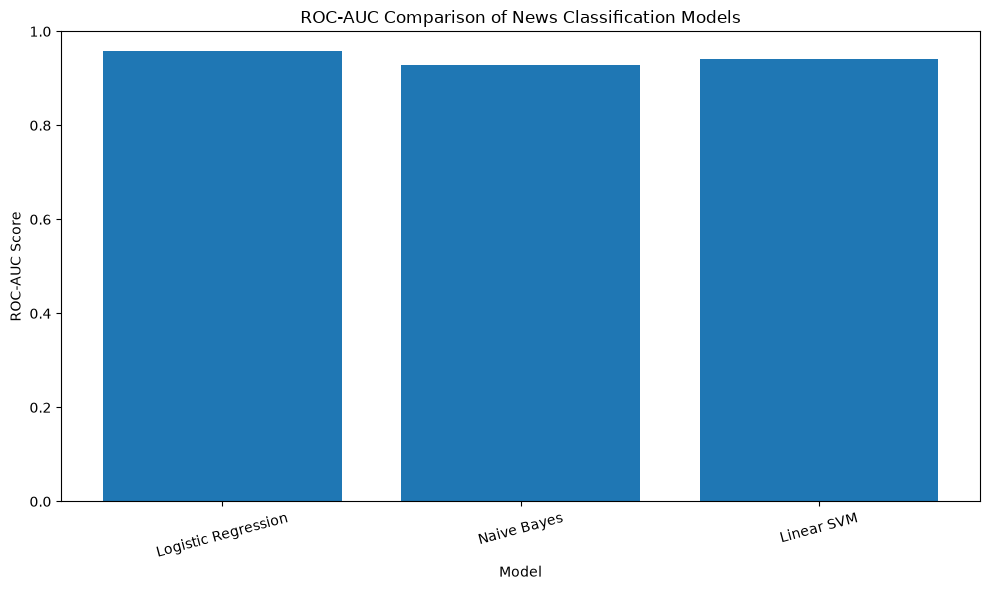

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Model"],
    results_df["ROC-AUC"]
)

plt.xlabel("Model")
plt.ylabel("ROC-AUC Score")
plt.title("ROC-AUC Comparison of News Classification Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [34]:
import os
import joblib

os.makedirs("../models", exist_ok=True)
os.makedirs("../outputs", exist_ok=True)

# Save trained models
joblib.dump(logistic_model, "../models/logistic_regression.pkl")
joblib.dump(nb_model, "../models/naive_bayes.pkl")
joblib.dump(svm_model, "../models/linear_svm.pkl")

# Save TF-IDF vectorizer
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Models and TF-IDF vectorizer saved successfully!")

Models and TF-IDF vectorizer saved successfully!


In [35]:
results_df.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [36]:
roc_auc_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],
    "ROC-AUC": [
        logistic_auc,
        nb_auc,
        svm_auc
    ]
})

roc_auc_results.to_csv(
    "../outputs/roc_auc_results.csv",
    index=False
)

print("ROC-AUC results saved successfully!")

ROC-AUC results saved successfully!


In [37]:
import os

os.makedirs("../data/processed", exist_ok=True)

processed_data = pd.DataFrame({
    "text": texts,
    "category": labels
})

processed_data.to_csv(
    "../data/processed/news_category_cleaned.csv",
    index=False
)

print("Processed dataset saved successfully!")
print("Rows:", len(processed_data))

Processed dataset saved successfully!
Rows: 209527


In [38]:
import joblib

model = joblib.load("../models/logistic_regression.pkl")

print("Logistic Regression model loaded successfully!")
print(type(model))

Logistic Regression model loaded successfully!
<class 'sklearn.linear_model._logistic.LogisticRegression'>


In [39]:
import joblib

naive_bayes_model = joblib.load("../models/naive_bayes.pkl")

print("Naive Bayes model loaded successfully!")
print(type(naive_bayes_model))

Naive Bayes model loaded successfully!
<class 'sklearn.naive_bayes.MultinomialNB'>


In [40]:
linear_svm_model = joblib.load("../models/linear_svm.pkl")

print("Linear SVM model loaded successfully!")
print(type(linear_svm_model))

Linear SVM model loaded successfully!
<class 'sklearn.svm._classes.LinearSVC'>


In [41]:
tfidf_vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")

print("TF-IDF vectorizer loaded successfully!")
print(type(tfidf_vectorizer))

TF-IDF vectorizer loaded successfully!
<class 'sklearn.feature_extraction.text.TfidfVectorizer'>


In [42]:
print("====================================")
print("SAVED FILE VERIFICATION")
print("====================================")

print("✓ Logistic Regression loaded")
print("✓ Naive Bayes loaded")
print("✓ Linear SVM loaded")
print("✓ TF-IDF Vectorizer loaded")

print("====================================")
print("All saved models and vectorizer are working!")
print("====================================")

SAVED FILE VERIFICATION
✓ Logistic Regression loaded
✓ Naive Bayes loaded
✓ Linear SVM loaded
✓ TF-IDF Vectorizer loaded
All saved models and vectorizer are working!
